# 02 · Train and evaluate

Trains the three models on the experiments defined in `plans/01_data_and_splits.md` §6, and writes the results.

- **Design:** `plans/02_train_eval.md`.
- **Reads:** `data/manifest.csv`. This notebook never re-splits.
- **Writes** (under `PROJECT`, i.e. Google Drive on Colab) into `models/<variant>/` and `results/<variant>/`: models, predictions, histories, `runs.csv`, `results.md` and the figures. The variant is `crop` (default) or `fitpad` (no crop); smoke runs go to `smoke/`.

**How to use it**
1. Runtime → Change runtime type → **GPU** (T4 is enough).
2. First run with `SMOKE = True`. That's 64 training images and 1 epoch per stage, for all three models, to check the pipeline. Outputs go to `models/smoke/` and `results/smoke/`.
3. Then set `SMOKE = False` and `FIRST_ONLY = True`. This trains MobileNetV3-Small on E1, seed 42, and shows validation scores.
4. Then set `FIRST_ONLY = False` to run the remaining 14 runs. A run that is already saved on Drive is skipped, so after a disconnect, just run all cells again.
5. **Test scores stay hidden (`SHOW_TEST = False`) while you develop.** Fix bugs, try settings and compare models on validation scores only. When the settings are frozen, set `SHOW_TEST = True` and run the evaluation cells once.

In [29]:
import csv, json, math, random, shutil, time, zipfile, collections
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps

# --- Run settings --------------------------------------------------------------
SMOKE = False        # True: tiny pipeline check (64 train images, 1 epoch per stage, E1 seed 42 only)
FIRST_ONLY = False    # True: only MobileNetV3-Small, E1, seed 42. Set False for the full matrix
SHOW_TEST = True    # keep False while developing; True once settings are frozen (plan §7)

MODELS = ['mnv3s', 'effb0', 'baseline']
RUNS = [('E1', s) for s in (42, 43, 44)] + [('E2a', 42), ('E2b', 42)]
EXPECTED_MANIFEST_ROWS = 1123   # the leakage-fixed manifest; the old one had 1132
EXPECTED_TEST = {'E1': 161, 'E2a': 724, 'E2b': 399}

IMG, BATCH, PATIENCE = 224, 32, 4
EPOCHS = {'stage1': 10, 'stage2': 20, 'baseline': 40}
LR = {'stage1': 1e-3, 'stage2': 1e-4, 'baseline': 1e-3}   # run 3 trial: stage 2 was 1e-5 / 15 epochs
UNFREEZE_TOP = 0.30
CROP_TO_BERRY = True  # crop each photo to the berry before resizing (decided on val, see plans/02 §3)
CROP_MARGIN = 0.15    # margin around the berry box, as a fraction of its size
RUN_TAG = 'lr1e-4'    # CHANGE THIS whenever you change a training setting; '' for none
VARIANT = ('crop' if CROP_TO_BERRY else 'fitpad') + (f'_{RUN_TAG}' if RUN_TAG else '')   # each variant gets its own output folders
RECALL_TARGET = 0.95  # secondary threshold: chosen on val to reach this damaged recall
BASELINE_PATIENCE = 8       # training from scratch is noisier than fine-tuning
BASELINE_BN_MOMENTUM = 0.9  # Keras default 0.99 left BatchNorm's running averages unsettled after ~25 steps/epoch:
                            # in the first full matrix the baseline called every val image 'damaged'
REPLACE_CHANGED = ['baseline']  # models whose finished runs may be retrained in place when their settings changed

# --- Where things live (same as notebook 01) ----------------------------------
# PROJECT: outputs are written here (Google Drive on Colab).
# ROOT:    images are read from here (a fast local copy on Colab). manifest paths are relative to ROOT.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/seventx_prototype')  # change if you put the folder elsewhere
    ROOT = Path('/content/seventx')
    if not (ROOT / 'dataset').exists():
        if (PROJECT / 'dataset.zip').exists():
            with zipfile.ZipFile(PROJECT / 'dataset.zip') as z:
                z.extractall(ROOT)
        else:
            shutil.copytree(PROJECT / 'dataset', ROOT / 'dataset')
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
    ROOT = PROJECT

sub = 'smoke' if SMOKE else VARIANT
MODELS_DIR = PROJECT / 'models' / sub
RESULTS_DIR = PROJECT / 'results' / sub
PRED_DIR, HIST_DIR = RESULTS_DIR / 'preds', RESULTS_DIR / 'history'
for d in (MODELS_DIR, PRED_DIR, HIST_DIR):
    d.mkdir(parents=True, exist_ok=True)
if SMOKE:
    MODELS, RUNS = ['mnv3s', 'effb0', 'baseline'], [('E1', 42)]
    EPOCHS = {'stage1': 1, 'stage2': 1, 'baseline': 1}
elif FIRST_ONLY:
    MODELS, RUNS = ['mnv3s'], [('E1', 42)]
print('images from', ROOT, '| outputs to', RESULTS_DIR, '| SMOKE', SMOKE, '| FIRST_ONLY', FIRST_ONLY,
      '| SHOW_TEST', SHOW_TEST, '| CROP_TO_BERRY', CROP_TO_BERRY, '| VARIANT', VARIANT)
print('stage 2: lr', LR['stage2'], '| up to', EPOCHS['stage2'], 'epochs')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
images from /content/seventx | outputs to /content/drive/MyDrive/seventx_prototype/results/crop_lr1e-4 | SMOKE False | FIRST_ONLY False | SHOW_TEST True | CROP_TO_BERRY True | VARIANT crop_lr1e-4
stage 2: lr 0.0001 | up to 20 epochs


In [30]:
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt

tf.get_logger().setLevel('ERROR')   # hides harmless 'tf.function retracing' warnings (a new model is built per run)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
if not tf.config.list_physical_devices('GPU'):
    print('WARNING: no GPU. On Colab: Runtime -> Change runtime type -> GPU. Training will be very slow on CPU.')

TensorFlow 2.21.0 | Keras 3.13.2


## 1. Manifest and image cache

In [31]:
with open(PROJECT / 'data' / 'manifest.csv', newline='') as f:
    M = list(csv.DictReader(f))
assert len(M) == EXPECTED_MANIFEST_ROWS, (
    f'manifest has {len(M)} rows, expected {EXPECTED_MANIFEST_ROWS}. '
    'Upload the new data/manifest.csv from notebook 01 (the old one leaks).')
for r in M:
    r['y'] = 1 if r['label'] == 'damaged' else 0
    r['multi_berry'] = int(r['multi_berry'])
Y = np.array([r['y'] for r in M], dtype=np.float32)
print(len(M), 'images:', collections.Counter(r['label'] for r in M))

1123 images: Counter({'good': 574, 'damaged': 549})


Each image is decoded once, **cropped to the berry** (`CROP_TO_BERRY`), and fitted inside 224×224, keeping the aspect ratio. The crop finds coloured pixels that differ from the background, takes their box, adds a 15% margin and makes it square. Without it, a Mahendra berry is only about 60 px wide at 224×224 and small bruises vanish; the first run scored 80% on Mahendra val against 91% on Mendeley. Piles and crates fill their photo, so they barely change. **The app must apply the same crop** (notebook 03 exports it).

The image is padded with its own **median border colour**, not black. Mahendra photos are always 4:3, so black bars would only ever appear on one source and give the model a cue that has nothing to do with the berry. EXIF rotation is applied, because phone photos can be stored sideways.

The cache lives in `ROOT/cache` (local disk on Colab, not Drive), one file per variant, and is rebuilt if the manifest changes.

In [32]:
def berry_box(a, margin=CROP_MARGIN):
    # Bounding box of the berry (or pile): coloured pixels that differ from the median border colour.
    # Returns (x0, y0, x1, y1) in pixels of `a`, squared and with a margin, or None if nothing is found.
    h, w = a.shape[:2]
    img = Image.fromarray(a).resize((256, 256))
    small = np.asarray(img, dtype=np.int16)
    sat = np.asarray(img.convert('HSV'), dtype=np.int16)[..., 1]
    bg = np.median(np.concatenate([small[0], small[-1], small[:, 0], small[:, -1]]), axis=0)
    # Berry pixels differ from the background AND are coloured. Shadows and the blue tint at the
    # Mahendra webcam edge differ from the background too, but are washed out (low saturation).
    mask = (np.abs(small - bg).sum(-1) > 60) & (sat > 70)
    rows, cols = mask.mean(1) > 0.8, mask.mean(0) > 0.8
    mask[rows, :] = False      # full-width lines, e.g. the dark line along the Mahendra webcam edge
    mask[:, cols] = False
    ys, xs = np.where(mask)
    if len(ys) < 50:
        return None
    (y0, y1), (x0, x1) = np.percentile(ys, [1, 99]) * h / 256, np.percentile(xs, [1, 99]) * w / 256
    side = max(x1 - x0, y1 - y0) * (1 + 2 * margin)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    box = (max(0, cx - side / 2), max(0, cy - side / 2), min(w, cx + side / 2), min(h, cy + side / 2))
    return tuple(int(round(v)) for v in box)

def fit_pad(path, size=IMG, crop=CROP_TO_BERRY):
    with Image.open(path) as im:
        im.draft('RGB', (size * 4, size * 4))   # decode big JPEGs at reduced size: much faster
        im = ImageOps.exif_transpose(im).convert('RGB')
        a = np.asarray(im)
        border = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
        bg = tuple(int(v) for v in np.median(border, axis=0))
        if crop:
            box = berry_box(a)
            if box is not None:
                im = im.crop(box)
        im.thumbnail((size, size), Image.LANCZOS)
        canvas = Image.new('RGB', (size, size), bg)
        canvas.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
        return np.asarray(canvas, dtype=np.uint8)

cache_dir = ROOT / 'cache'
cache_dir.mkdir(exist_ok=True)
x_path, p_path = cache_dir / f'images_{IMG}_{VARIANT}.npy', cache_dir / f'images_{IMG}_{VARIANT}_paths.json'
paths = [r['path'] for r in M]
if x_path.exists() and p_path.exists() and json.loads(p_path.read_text()) == paths:
    X = np.load(x_path)
    print('loaded cache', X.shape)
else:
    t0 = time.time()
    X = np.stack([fit_pad(ROOT / p) for p in paths])
    np.save(x_path, X)
    p_path.write_text(json.dumps(paths))
    print('built cache', X.shape, f'in {time.time() - t0:.0f} s')

loaded cache (1123, 224, 224, 3)


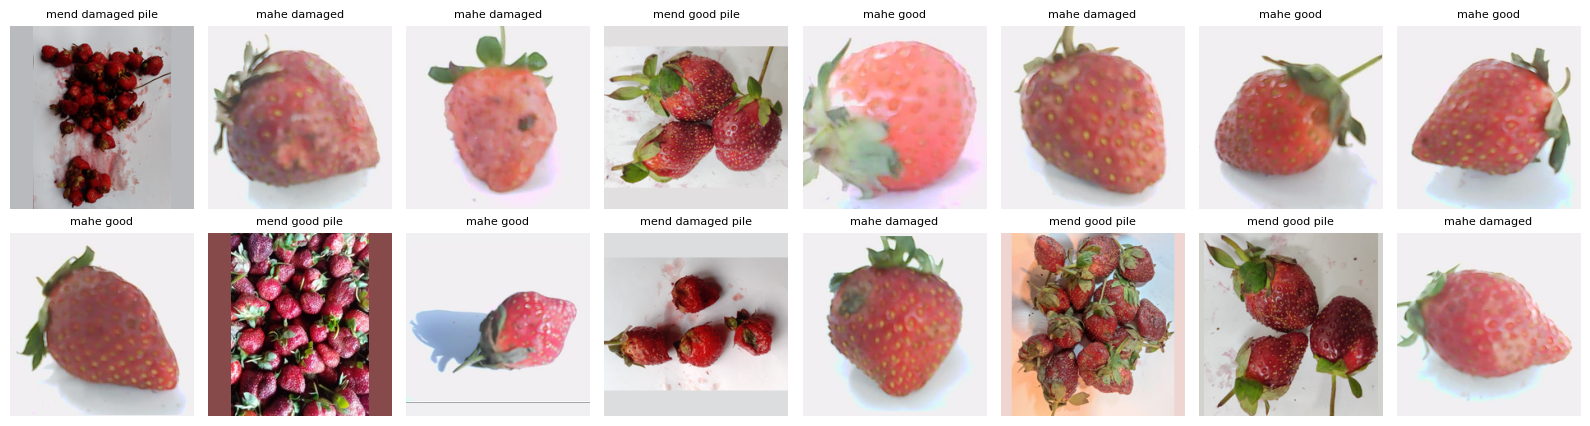

In [33]:
# Sanity check: 16 cached images with source, label and multi_berry.
rng = np.random.default_rng(0)
show = rng.choice(len(M), 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, i in zip(axes.flat, show):
    ax.imshow(X[i]); ax.axis('off')
    ax.set_title(f"{M[i]['source'][:4]} {M[i]['label']}" + (' pile' if M[i]['multi_berry'] else ''), fontsize=8)
plt.tight_layout(); plt.show()

## 2. Experiment index sets

Built from manifest columns only. Validation always comes from the **training** source, so in E2 the test dataset stays completely unseen.

In [34]:
def idx(cond):
    return np.array([i for i, r in enumerate(M) if cond(r)], dtype=np.int64)

EXPS = {
    'E1':  dict(train=idx(lambda r: r['split'] == 'train'),
                val=idx(lambda r: r['split'] == 'val'),
                test=idx(lambda r: r['split'] == 'test')),
    'E2a': dict(train=idx(lambda r: r['source'] == 'mendeley' and r['split'] == 'train'),
                val=idx(lambda r: r['source'] == 'mendeley' and r['split'] == 'val'),
                test=idx(lambda r: r['source'] == 'mahendra')),
    'E2b': dict(train=idx(lambda r: r['source'] == 'mahendra' and r['split'] == 'train'),
                val=idx(lambda r: r['source'] == 'mahendra' and r['split'] == 'val'),
                test=idx(lambda r: r['source'] == 'mendeley')),
}
for e, s in EXPS.items():
    assert len(s['test']) == EXPECTED_TEST[e], (e, len(s['test']))
if SMOKE:
    pick = np.random.default_rng(0)
    for s in EXPS.values():
        for part in ('train', 'val'):   # at most 64 each (E2a has only 58 val images)
            s[part] = np.sort(pick.choice(s[part], min(64, len(s[part])), replace=False))
for e, s in EXPS.items():
    print(e, {k: len(v) for k, v in s.items()})

E1 {'train': 797, 'val': 165, 'test': 161}
E2a {'train': 284, 'val': 58, 'test': 724}
E2b {'train': 513, 'val': 107, 'test': 399}


## 3. Augmentation and input pipeline

Augmentation runs in `tf.data` on **training batches only**, and is kept out of the model so the exported model stays clean. Pixels stay in 0–255: the pretrained backbones rescale inside the model.

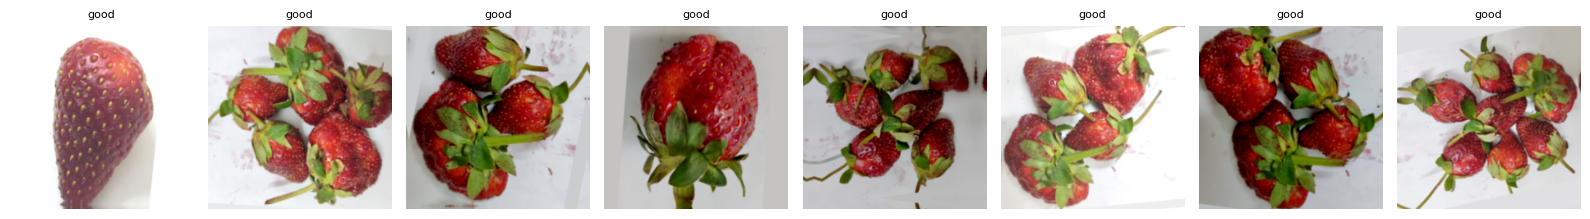

In [35]:
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(20 / 360, fill_mode='reflect'),
    layers.RandomZoom(0.15, fill_mode='reflect'),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name='augment')

AUTOTUNE = tf.data.AUTOTUNE

def make_ds(ix, train=False, seed=0):
    ds = tf.data.Dataset.from_tensor_slices((X[ix], Y[ix]))
    if train:
        ds = ds.shuffle(len(ix), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    if train:
        ds = ds.map(lambda a, b: (tf.clip_by_value(augment(a, training=True), 0.0, 255.0), b),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

# Look at a few augmented training images.
xb, yb = next(iter(make_ds(EXPS['E1']['train'][:8], train=True, seed=1)))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, im, y in zip(axes, xb.numpy(), yb.numpy()):
    ax.imshow(im.astype('uint8')); ax.axis('off'); ax.set_title('damaged' if y else 'good', fontsize=8)
plt.tight_layout(); plt.show()

## 4. Models

Every model is: input → backbone → global average pooling → dropout 0.2 → Dense(1, sigmoid). The output is **P(damaged)**.

| Name | Backbone |
| --- | --- |
| `baseline` | `Rescaling(1/255)`, then 4 blocks of Conv3×3, BatchNorm, ReLU, MaxPool (32, 64, 128, 128 filters), trained from scratch |
| `mnv3s` | MobileNetV3-Small, ImageNet weights. It rescales its input inside the model, so feed raw 0–255 |
| `effb0` | EfficientNet-B0, ImageNet weights. Same: feed raw 0–255 |

The pretrained backbones are called with `training=False`, so their BatchNorm layers stay in inference mode in both training stages.

In [36]:
def build(name):
    inp = keras.Input((IMG, IMG, 3), name='image')
    backbone = None
    if name == 'baseline':
        x = layers.Rescaling(1 / 255)(inp)
        for f in (32, 64, 128, 128):
            x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
            x = layers.BatchNormalization(momentum=BASELINE_BN_MOMENTUM)(x)
            x = layers.ReLU()(x)
            x = layers.MaxPooling2D()(x)
    else:
        if name == 'mnv3s':
            backbone = keras.applications.MobileNetV3Small(
                input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet', include_preprocessing=True)
        elif name == 'effb0':
            backbone = keras.applications.EfficientNetB0(input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet')
        else:
            raise ValueError(name)
        backbone.trainable = False
        x = backbone(inp, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.2, name='dropout')(x)
    out = layers.Dense(1, activation='sigmoid', name='p_damaged')(x)
    return keras.Model(inp, out, name=name), backbone

def unfreeze_top(backbone, frac=UNFREEZE_TOP):
    # Top `frac` of the backbone's layers become trainable; BatchNorm layers stay frozen.
    backbone.trainable = True
    cut = int(len(backbone.layers) * (1 - frac))
    for i, layer in enumerate(backbone.layers):
        layer.trainable = i >= cut and not isinstance(layer, layers.BatchNormalization)

for n in MODELS:
    m, _ = build(n)
    print(f'{n:9s} {m.count_params():>10,} parameters')
    del m
keras.backend.clear_session()

mnv3s        939,697 parameters
effb0      4,050,852 parameters
baseline     242,017 parameters


## 5. Training

- **Pretrained models:** stage 1 trains the head with the backbone frozen (Adam 1e-3, ≤10 epochs). Stage 2 unfreezes the top 30% of backbone layers, except BatchNorm (Adam `LR['stage2']`, ≤`EPOCHS['stage2']` epochs; see the settings cell).
- **Run tag:** each combination of settings writes to its own folder (`VARIANT`). If you change a setting, change `RUN_TAG`. A finished run trained with different settings is never silently skipped; the notebook stops and asks for a new tag.
- **Baseline:** one stage (Adam 1e-3, ≤40 epochs).
- **All runs:** batch 32, early stopping on validation loss (patience 4). The weights with the lowest validation loss across both stages are kept.
- **Resume-safe:** a run whose model and prediction files already exist on Drive is skipped.

In [37]:
class KeepBest(keras.callbacks.Callback):
    # Remembers the weights with the lowest val_loss, across several fit() calls (both stages).
    def __init__(self):
        super().__init__()
        self.best, self.weights, self.where = np.inf, None, None
        self.stage = ''

    def on_epoch_end(self, epoch, logs=None):
        v = logs['val_loss']
        if v < self.best:
            self.best, self.where = v, f'{self.stage} epoch {epoch + 1}'
            self.weights = {w.path: w.numpy() for w in self.model.weights}

    def restore(self, model):
        for w in model.weights:
            w.assign(self.weights[w.path])

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
                  metrics=[keras.metrics.BinaryAccuracy(name='acc'), keras.metrics.Recall(name='recall')])

def fit_stage(model, tr, va, epochs, keep, stage, patience=PATIENCE):
    keep.stage = stage
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience)
    h = model.fit(tr, validation_data=va, epochs=epochs, callbacks=[keep, es], verbose=2)
    return {k: [float(v) for v in vs] for k, vs in h.history.items()}

def write_preds(path, ix, probs):
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['path', 'source', 'label', 'multi_berry', 'prob_damaged'])
        for i, p in zip(ix, probs):
            r = M[i]
            w.writerow([r['path'], r['source'], r['label'], r['multi_berry'], f'{p:.6f}'])

# Settings that change what a run learns. Saved with each run and checked before skipping one.
BASE_CONFIG = dict(img=IMG, batch=BATCH, patience=PATIENCE, epochs=EPOCHS, lr=LR, unfreeze_top=UNFREEZE_TOP,
                   crop_to_berry=CROP_TO_BERRY, crop_margin=CROP_MARGIN)

def config_for(name):
    c = dict(BASE_CONFIG)
    if name == 'baseline':
        c.update(baseline_patience=BASELINE_PATIENCE, bn_momentum=BASELINE_BN_MOMENTUM)
    return json.loads(json.dumps(c))   # same form as after a JSON round trip, so comparisons work

def run(exp, name, seed):
    tag = f'{exp}_{name}_s{seed}'
    files = [MODELS_DIR / f'{tag}.keras', PRED_DIR / f'{tag}.csv', PRED_DIR / f'{tag}_val.csv', HIST_DIR / f'{tag}.json']
    cfg = config_for(name)
    if all(f.exists() for f in files):
        old = json.loads(files[3].read_text()).get('config')
        if old is None or old == cfg:
            print('skip (already done):', tag)
            return
        if name not in REPLACE_CHANGED:
            raise RuntimeError(f'{tag} in {MODELS_DIR} was trained with other settings: {old}. '
                               'Set a new RUN_TAG so this run gets its own folder.')
        print('settings changed, retraining in place:', tag)
    print(f'\n=== {tag} ===')
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    s = EXPS[exp]
    tr, va = make_ds(s['train'], train=True, seed=seed), make_ds(s['val'])
    model, backbone = build(name)
    keep, hist, t0 = KeepBest(), {}, time.time()
    if backbone is None:
        compile_model(model, LR['baseline'])
        hist['baseline'] = fit_stage(model, tr, va, EPOCHS['baseline'], keep, 'baseline', patience=BASELINE_PATIENCE)
    else:
        compile_model(model, LR['stage1'])
        hist['stage1'] = fit_stage(model, tr, va, EPOCHS['stage1'], keep, 'stage1')
        keep.restore(model)                       # stage 2 starts from the best stage-1 weights
        unfreeze_top(backbone)
        compile_model(model, LR['stage2'])
        hist['stage2'] = fit_stage(model, tr, va, EPOCHS['stage2'], keep, 'stage2')
    keep.restore(model)
    seconds = time.time() - t0
    model.save(str(files[0]))
    write_preds(files[2], s['val'], model.predict(make_ds(s['val']), verbose=0).ravel())
    write_preds(files[1], s['test'], model.predict(make_ds(s['test']), verbose=0).ravel())
    files[3].write_text(json.dumps(dict(
        exp=exp, model=name, seed=seed, history=hist, best_val_loss=float(keep.best), best_at=keep.where,
        crop_to_berry=CROP_TO_BERRY, crop_margin=CROP_MARGIN, config=cfg, variant=VARIANT,
        train_seconds=round(seconds, 1), params=int(model.count_params()),
        keras_mb=round(files[0].stat().st_size / 1e6, 2),
        tf=tf.__version__, keras=keras.__version__), indent=1))
    print(f'{tag}: best val_loss {keep.best:.4f} at {keep.where}, {seconds:.0f} s')

for name in MODELS:
    for exp, seed in RUNS:
        run(exp, name, seed)

skip (already done): E1_mnv3s_s42
skip (already done): E1_mnv3s_s43
skip (already done): E1_mnv3s_s44
skip (already done): E2a_mnv3s_s42
skip (already done): E2b_mnv3s_s42
skip (already done): E1_effb0_s42
skip (already done): E1_effb0_s43
skip (already done): E1_effb0_s44
skip (already done): E2a_effb0_s42
skip (already done): E2b_effb0_s42
skip (already done): E1_baseline_s42
skip (already done): E1_baseline_s43
skip (already done): E1_baseline_s44
skip (already done): E2a_baseline_s42
skip (already done): E2b_baseline_s42


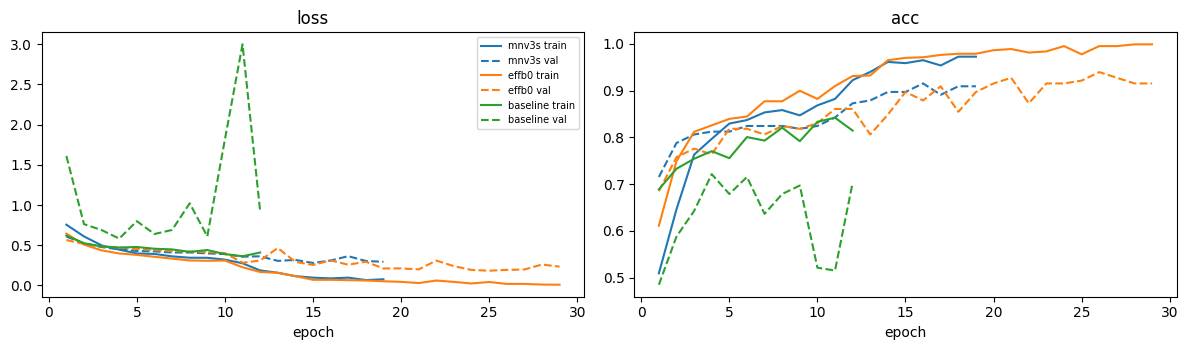

In [38]:
# Training curves of the E1 seed-42 runs (stage 2 continues after stage 1).
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for name in MODELS:
    f = HIST_DIR / f'E1_{name}_s42.json'
    if not f.exists():
        continue
    h = json.loads(f.read_text())['history']
    for ax, key in zip(axes, ('loss', 'acc')):
        tr = [v for st in h.values() for v in st[key]]
        va = [v for st in h.values() for v in st['val_' + key]]
        line, = ax.plot(range(1, len(tr) + 1), tr, label=f'{name} train')
        ax.plot(range(1, len(va) + 1), va, '--', color=line.get_color(), label=f'{name} val')
        ax.set_title(key); ax.set_xlabel('epoch')
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'curves_E1_s42.png', dpi=120); plt.show()

## 6. Evaluation

Every metric is computed from the saved prediction files, so this part can be rerun without retraining.

- **Subsets:** all images, single-berry only (`multi_berry == 0`), and each source.
- **Thresholds:** 0.5, and a secondary threshold chosen on **val** to reach damaged recall ≥ 0.95 (only lowered, never raised above 0.5).
- **Test-set discipline:** with `SHOW_TEST = False`, only validation scores are computed. Choose the model on validation scores (`MODEL_PLAN.md` §6).

In [39]:
def read_preds(path):
    with open(path, newline='') as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        r['y'] = 1 if r['label'] == 'damaged' else 0
        r['p'] = float(r['prob_damaged'])
        r['multi_berry'] = int(r['multi_berry'])
    return rows

def scores(rows, thr):
    y = np.array([r['y'] for r in rows]); p = np.array([r['p'] for r in rows])
    pred = (p >= thr).astype(int)
    tp, fn = int(((pred == 1) & (y == 1)).sum()), int(((pred == 0) & (y == 1)).sum())
    tn, fp = int(((pred == 0) & (y == 0)).sum()), int(((pred == 1) & (y == 0)).sum())
    div = lambda a, b: a / b if b else float('nan')
    out = dict(n=len(y), acc=div(tp + tn, len(y)), tp=tp, fn=fn, tn=tn, fp=fp)
    for cls, (c, m, f) in {'damaged': (tp, fn, fp), 'good': (tn, fp, fn)}.items():
        prec, rec = div(c, c + f), div(c, c + m)
        out[f'{cls}_precision'], out[f'{cls}_recall'] = prec, rec
        out[f'{cls}_f1'] = div(2 * prec * rec, prec + rec) if not (math.isnan(prec) or math.isnan(rec)) else float('nan')
    return out

def recall_threshold(val_rows, target=RECALL_TARGET):
    # Largest threshold that still gives damaged recall >= target on val; never above 0.5.
    p = np.sort([r['p'] for r in val_rows if r['y'] == 1])
    if len(p) == 0:
        return 0.5
    k = int(math.floor((1 - target) * len(p)))
    return float(min(p[k], 0.5))

SUBSETS = {
    'all': lambda r: True,
    'single': lambda r: r['multi_berry'] == 0,
    'mahendra': lambda r: r['source'] == 'mahendra',
    'mendeley': lambda r: r['source'] == 'mendeley',
}

records = []
for hist_file in sorted(HIST_DIR.glob('*.json')):
    info = json.loads(hist_file.read_text())
    tag = hist_file.stem
    val_rows = read_preds(PRED_DIR / f'{tag}_val.csv')
    thresholds = {'0.5': 0.5, f'val_recall{int(RECALL_TARGET * 100)}': recall_threshold(val_rows)}
    evals = [('val', val_rows)]
    if SHOW_TEST:
        test_rows = read_preds(PRED_DIR / f'{tag}.csv')
        assert len(test_rows) == EXPECTED_TEST[info['exp']], (tag, len(test_rows))
        evals.append(('test', test_rows))
    for on, rows in evals:
        for subset, keep in SUBSETS.items():
            part = [r for r in rows if keep(r)]
            if not part:
                continue
            for thr_name, thr in thresholds.items():
                records.append(dict(exp=info['exp'], model=info['model'], seed=info['seed'], eval_on=on, subset=subset,
                                    threshold=thr_name, thr=round(thr, 4), **scores(part, thr),
                                    params=info['params'], keras_mb=info['keras_mb'], train_seconds=info['train_seconds']))

if records:
    with open(RESULTS_DIR / 'runs.csv', 'w', newline='') as f:
        w = csv.DictWriter(f, list(records[0]))
        w.writeheader(); w.writerows(records)
    print(len(records), 'rows ->', RESULTS_DIR / 'runs.csv', '| test included:', SHOW_TEST)
else:
    print('No finished runs yet: train first (section 5).')

def get(exp, model, on, subset='all', threshold='0.5', key='acc'):
    return [r[key] for r in records if (r['exp'], r['model'], r['eval_on'], r['subset'], r['threshold']) ==
            (exp, model, on, subset, threshold)]

# Plausibility flags (plan §5). Smoke runs are too small to mean anything, so they are not checked.
if SMOKE:
    print('SMOKE run: scores are meaningless (64 images, 1 epoch). Only check that everything ran.')
for name in ([] if SMOKE else MODELS):
    for on in ('val', 'test') if SHOW_TEST else ('val',):
        accs = get('E1', name, on)
        if name == 'mnv3s' and accs and (np.mean(accs) < 0.85 or max(accs) == 1.0):
            print(f'WARNING: mnv3s E1 {on} accuracy {np.mean(accs):.3f}. Below ~0.85 suggests a bug; 1.0 suggests leakage. Check before trusting it.')

216 rows -> /content/drive/MyDrive/seventx_prototype/results/crop_lr1e-4/runs.csv | test included: True


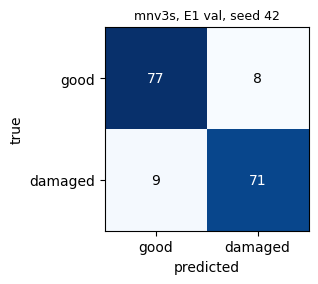

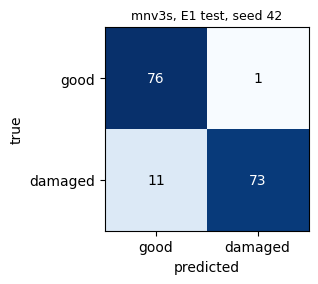

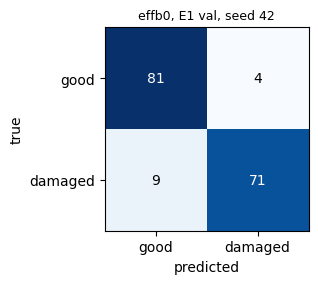

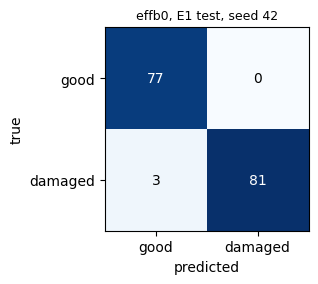

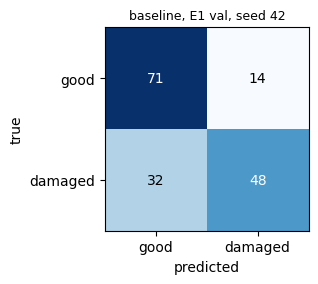

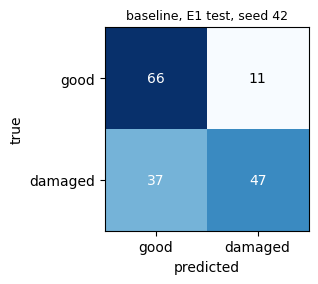

In [40]:
def confusion_png(name, on):
    tag = f'E1_{name}_s42'
    f = PRED_DIR / (f'{tag}_val.csv' if on == 'val' else f'{tag}.csv')
    if not f.exists():
        return None
    s = scores(read_preds(f), 0.5)
    cm = np.array([[s['tn'], s['fp']], [s['fn'], s['tp']]])
    fig, ax = plt.subplots(figsize=(3.2, 3))
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['good', 'damaged']); ax.set_yticks([0, 1], ['good', 'damaged'])
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{name}, E1 {on}, seed 42', fontsize=9)
    out = RESULTS_DIR / f'confusion_{name}_{on}.png'
    plt.tight_layout(); plt.savefig(out, dpi=120); plt.show()
    return out.name

CONFUSION = {(n, on): confusion_png(n, on) for n in MODELS for on in (('val', 'test') if SHOW_TEST else ('val',))}

## 7. Grad-CAM

Shows where the model looks. **Diagnose on val:** look at the val grid while developing, and make any changes based on it. The **test** grid is made once, with `SHOW_TEST = True`, for the results and the pitch.

The question is whether the heat sits on the berry, or on juice stains, the pile layout or the background. Write the answer by hand in `results/gradcam_notes.md`; `results.md` includes that file.

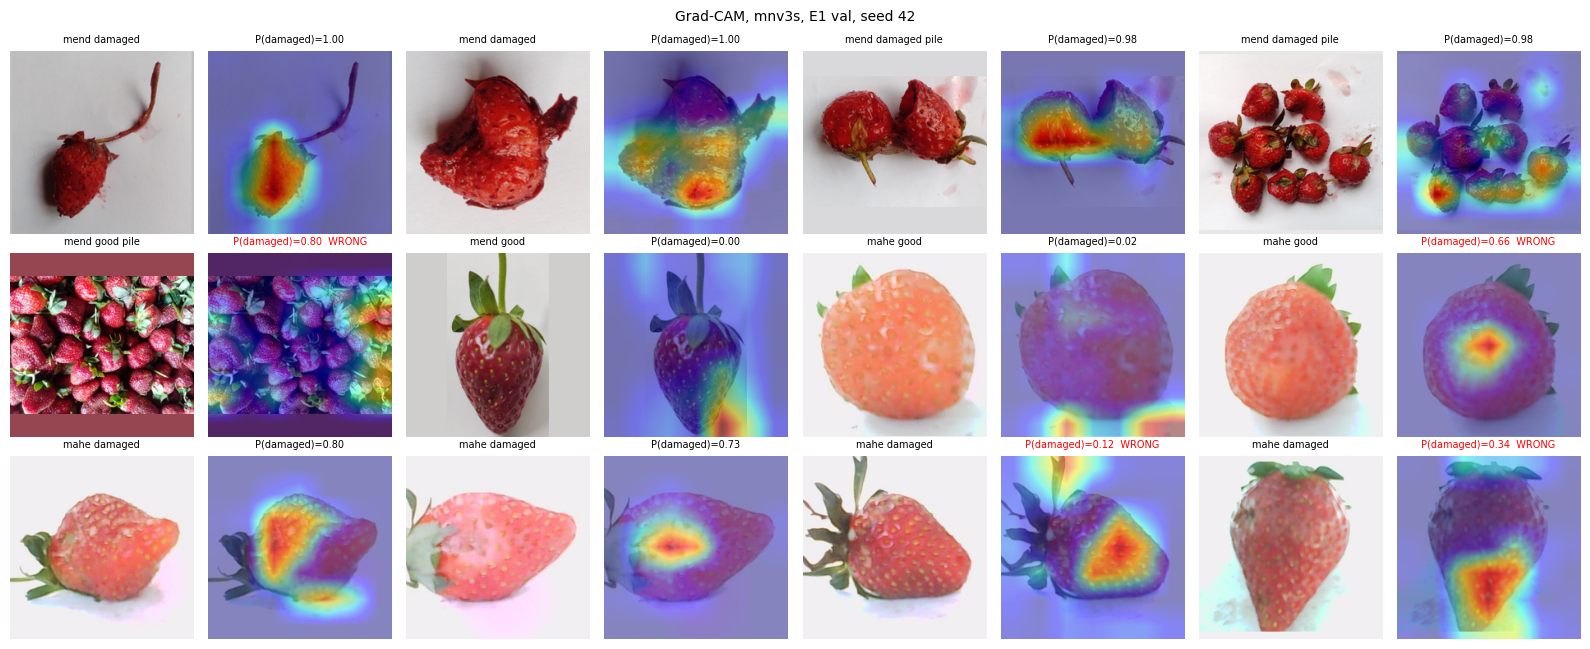

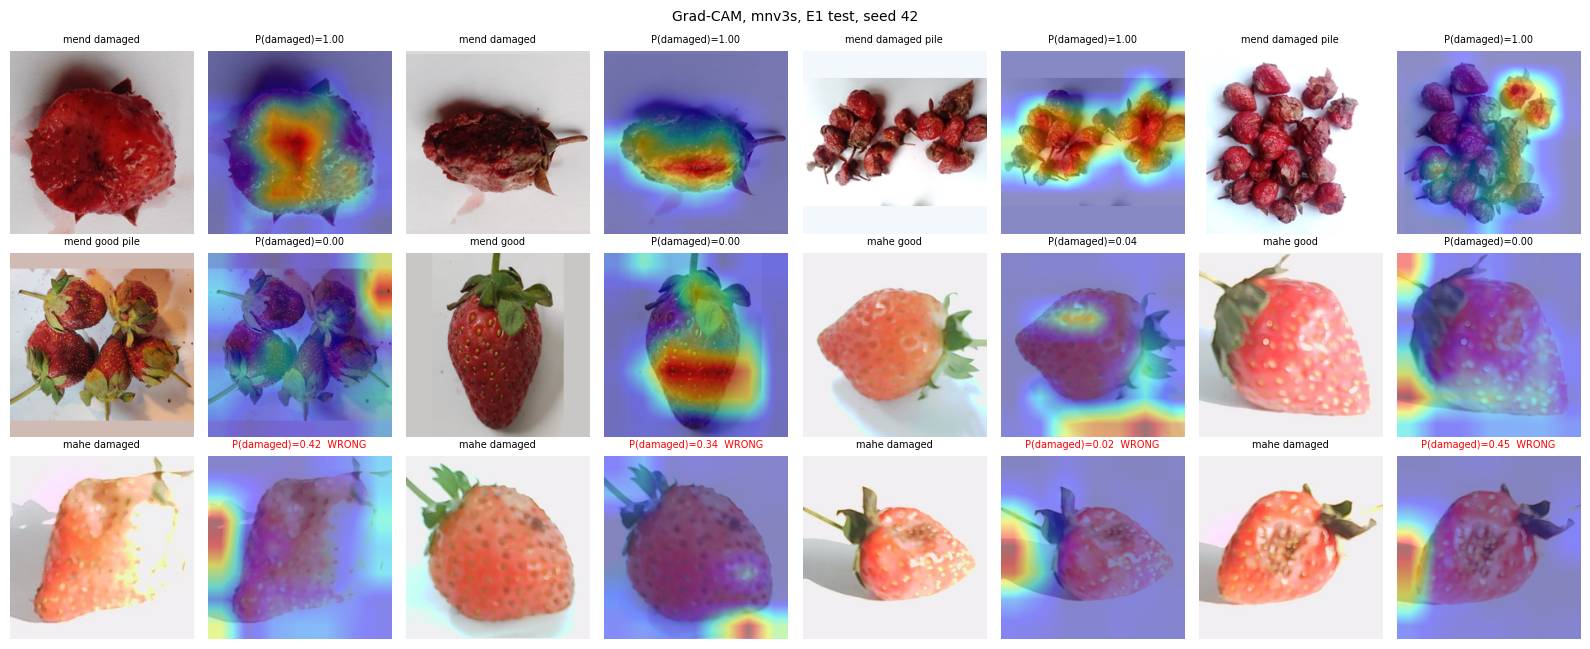

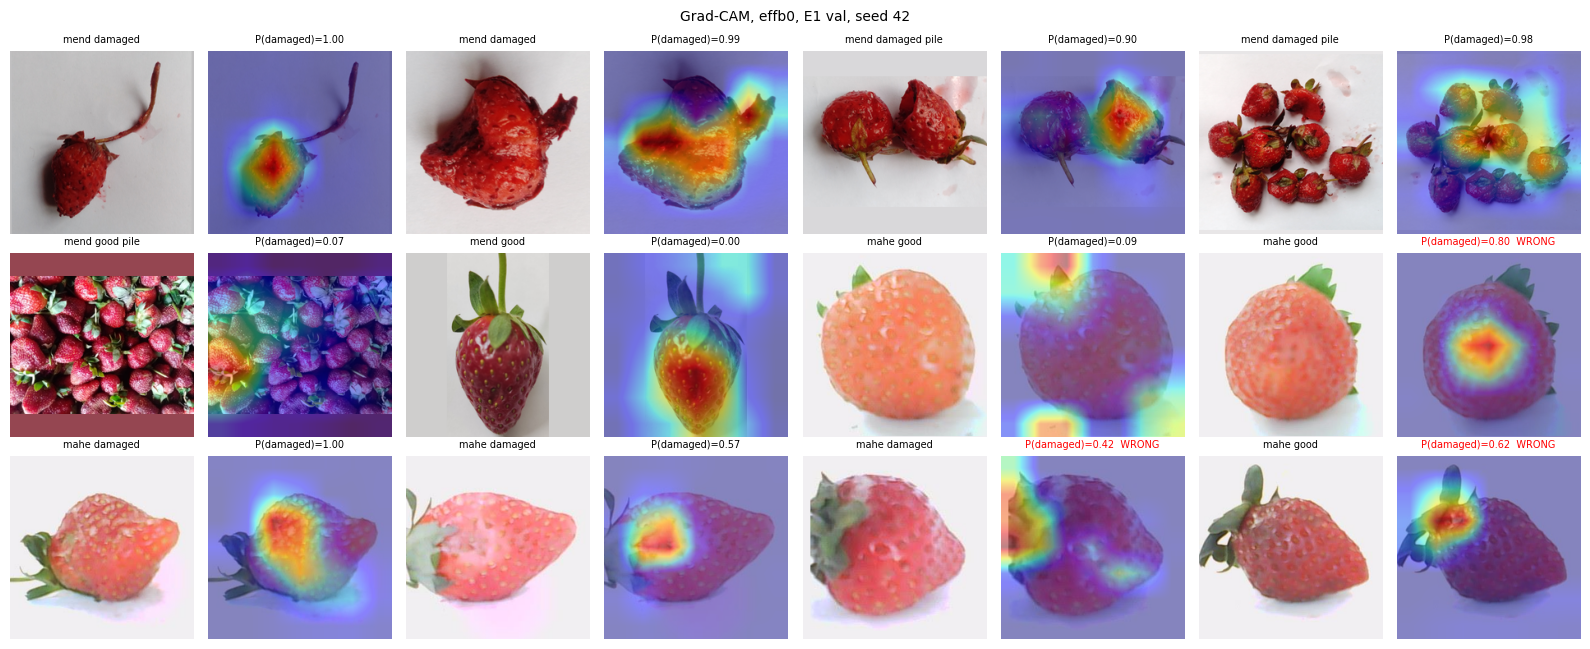

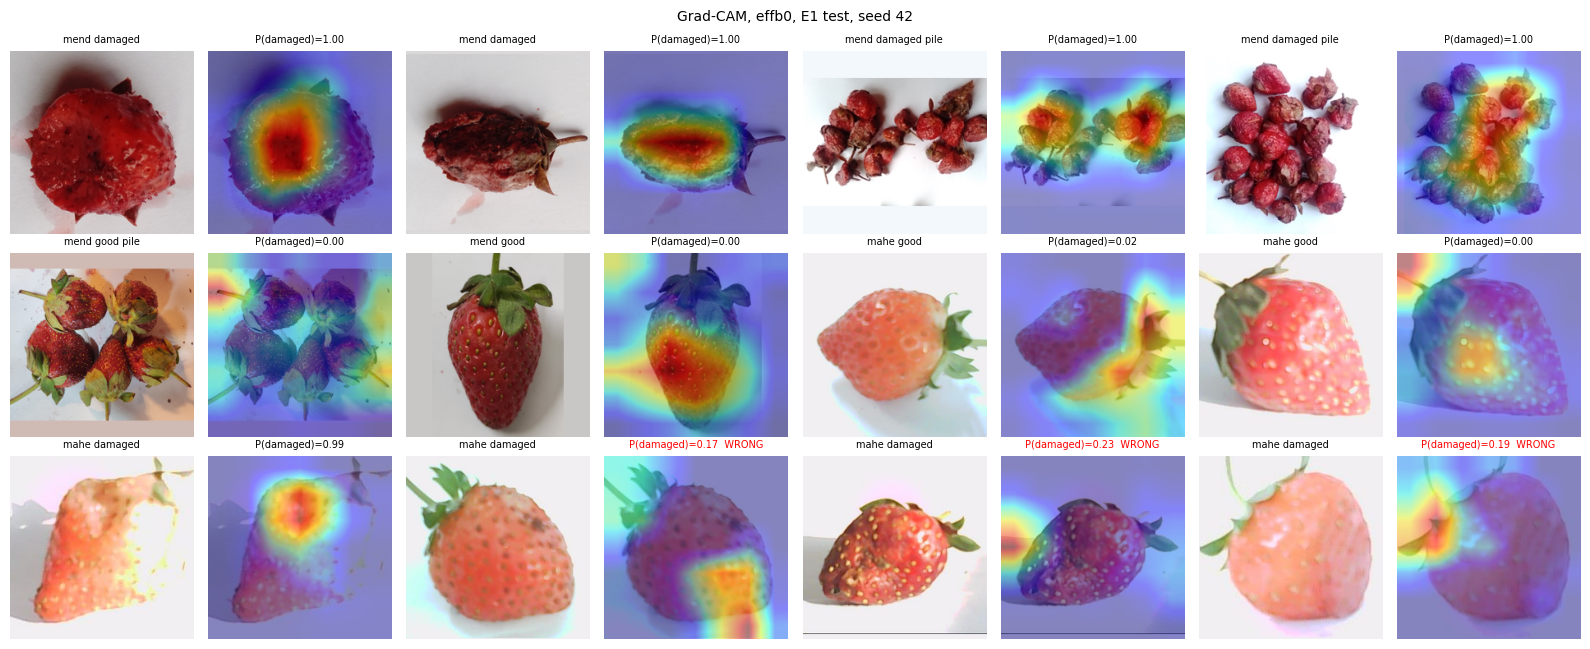

In [41]:
def gradcam(model, images):
    # Grad-CAM on the backbone's last feature map, for the predicted class.
    backbone = next(l for l in model.layers if isinstance(l, keras.Model))
    gap, dense = model.get_layer('gap'), model.get_layer('p_damaged')
    x = tf.convert_to_tensor(images, tf.float32)
    with tf.GradientTape() as tape:
        feat = backbone(x, training=False)
        tape.watch(feat)
        logit = tf.matmul(gap(feat), dense.kernel)[:, 0] + dense.bias[0]
        target = tf.where(logit >= 0, logit, -logit)   # explain the class the model predicted
    grads = tape.gradient(target, feat)
    cam = tf.nn.relu(tf.einsum('bhwc,bc->bhw', feat, tf.reduce_mean(grads, axis=(1, 2)))).numpy()
    cam /= cam.max(axis=(1, 2), keepdims=True) + 1e-8
    return tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0], tf.sigmoid(logit).numpy()

def pick_images(ix, preds_file, n_per=2, seed=0):
    rng = random.Random(seed)
    probs = {r['path']: r['p'] for r in read_preds(preds_file)}
    # 12 images: rotten Mendeley 2 single + 2 piles, fresh Mendeley 1 pile + 1 single,
    # Mahendra 2 good + 2 damaged, and up to 2 misclassified ones.
    wanted = [
        (lambda r: r['source'] == 'mendeley' and r['y'] == 1 and r['multi_berry'] == 0, 2),
        (lambda r: r['source'] == 'mendeley' and r['y'] == 1 and r['multi_berry'] == 1, 2),
        (lambda r: r['source'] == 'mendeley' and r['y'] == 0 and r['multi_berry'] == 1, 1),
        (lambda r: r['source'] == 'mendeley' and r['y'] == 0 and r['multi_berry'] == 0, 1),
        (lambda r: r['source'] == 'mahendra' and r['y'] == 0, 2),
        (lambda r: r['source'] == 'mahendra' and r['y'] == 1, 2),
    ]
    chosen = []
    for cond, n in wanted:
        pool = [int(i) for i in ix if cond(M[i]) and int(i) not in chosen]
        chosen += rng.sample(pool, min(n, len(pool)))
    wrong = [int(i) for i in ix if int(i) not in chosen and (probs[M[i]['path']] >= 0.5) != bool(M[i]['y'])]
    chosen += rng.sample(wrong, min(2, len(wrong)))
    return chosen

def gradcam_png(name, on):
    tag = f'E1_{name}_s42'
    mfile = MODELS_DIR / f'{tag}.keras'
    pfile = PRED_DIR / (f'{tag}_val.csv' if on == 'val' else f'{tag}.csv')
    if not (mfile.exists() and pfile.exists()):
        return None
    model = keras.models.load_model(str(mfile))
    chosen = pick_images(EXPS['E1'][on], pfile)
    cams, probs = gradcam(model, X[chosen])
    cols = 4
    rows_ = math.ceil(len(chosen) / cols)
    fig, axes = plt.subplots(rows_, cols * 2, figsize=(cols * 4, rows_ * 2.2))
    axes = np.atleast_2d(axes)
    for k in range(rows_ * cols):
        a_img, a_cam = axes[k // cols, (k % cols) * 2], axes[k // cols, (k % cols) * 2 + 1]
        a_img.axis('off'); a_cam.axis('off')
        if k >= len(chosen):
            continue
        r = M[chosen[k]]
        a_img.imshow(X[chosen[k]])
        a_img.set_title(f"{r['source'][:4]} {r['label']}{' pile' if r['multi_berry'] else ''}", fontsize=7)
        a_cam.imshow(X[chosen[k]]); a_cam.imshow(cams[k], cmap='jet', alpha=0.45)
        ok = (probs[k] >= 0.5) == bool(r['y'])
        a_cam.set_title(f'P(damaged)={probs[k]:.2f}' + ('' if ok else '  WRONG'), fontsize=7, color='black' if ok else 'red')
    fig.suptitle(f'Grad-CAM, {name}, E1 {on}, seed 42', fontsize=10)
    out = RESULTS_DIR / f'gradcam_{name}_{on}.png'
    plt.tight_layout(); plt.savefig(out, dpi=110); plt.show()
    del model
    keras.backend.clear_session()
    return out.name

GRADCAM = {(n, on): gradcam_png(n, on) for n in MODELS if n != 'baseline'
           for on in (('val', 'test') if SHOW_TEST else ('val',))}

## 8. `results/results.md`

Generated from `runs.csv`. The **val** columns decide the model (`MODEL_PLAN.md` §6); the test columns are reported. Notebook 03 adds the `.tflite` size and ms/image.

In [42]:
def ms(vals, pct=True):
    vals = [v for v in vals if not (isinstance(v, float) and math.isnan(v))]
    if not vals:
        return '–'
    f = (lambda v: f'{100 * v:.1f}') if pct else (lambda v: f'{v:.3g}')
    return f(np.mean(vals)) + (f' ± {f(np.std(vals, ddof=1))}' if len(vals) > 1 else '')

hidden = 'hidden'
L = ['# Results: strawberry good vs damaged', '',
     f"Generated by notebook 02. Test scores {'included' if SHOW_TEST else 'hidden (SHOW_TEST = False): choose the model on val first'}.",
     'E1 columns are mean ± sd over seeds 42/43/44; E2 is seed 42. Accuracy and recall in %, threshold 0.5.',
     'float32 MB is the size of the weights (params × 4 bytes). The .keras files are bigger because they also store the optimizer state.', '',
     '| Model | E1 val acc | E1 val damaged recall | E1 acc | E1 damaged recall | E1 single-berry acc | E2a acc | E2b acc | params | float32 MB | .tflite MB | ms / image |',
     '| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |']
for name in MODELS:
    p = get('E1', name, 'val', key='params') or get('E2a', name, 'val', key='params')
    t = (lambda *a, **k: ms(get(*a, **k))) if SHOW_TEST else (lambda *a, **k: hidden)
    L.append(f"| {name} | {ms(get('E1', name, 'val'))} | {ms(get('E1', name, 'val', key='damaged_recall'))} | "
             f"{t('E1', name, 'test')} | {t('E1', name, 'test', key='damaged_recall')} | {t('E1', name, 'test', subset='single')} | "
             f"{t('E2a', name, 'test')} | {t('E2b', name, 'test')} | {f'{p[0]:,}' if p else '–'} | {f'{p[0] * 4 / 1e6:.1f}' if p else '–'} | (nb 03) | (nb 03) |")

on_list = ('val', 'test') if SHOW_TEST else ('val',)
for on in on_list:
    L += ['', f'## E1 {on}: breakdown by subset (accuracy / damaged recall, %)', '',
          '| Model | all | single-berry | Mahendra | Mendeley |', '| --- | --- | --- | --- | --- |']
    for name in MODELS:
        cells = [f"{ms(get('E1', name, on, subset=s))} / {ms(get('E1', name, on, subset=s, key='damaged_recall'))}" for s in SUBSETS]
        L.append(f'| {name} | ' + ' | '.join(cells) + ' |')
    L += ['', f'Secondary threshold (chosen on val for damaged recall ≥ {int(RECALL_TARGET * 100)}%, E1 {on}):', '',
          '| Model | threshold | accuracy | damaged recall | good precision |', '| --- | --- | --- | --- | --- |']
    tn = f'val_recall{int(RECALL_TARGET * 100)}'
    for name in MODELS:
        L.append(f"| {name} | {ms(get('E1', name, on, threshold=tn, key='thr'), pct=False)} | {ms(get('E1', name, on, threshold=tn))} | "
                 f"{ms(get('E1', name, on, threshold=tn, key='damaged_recall'))} | {ms(get('E1', name, on, threshold=tn, key='good_precision'))} |")

L += ['', '## Figures', '']
L += [f'![confusion {n} {on}]({v})' for (n, on), v in CONFUSION.items() if v]
L += [f'![Grad-CAM {n} {on}]({v})' for (n, on), v in GRADCAM.items() if v]
if (RESULTS_DIR / 'curves_E1_s42.png').exists():
    L.append('![training curves](curves_E1_s42.png)')
notes = RESULTS_DIR / 'gradcam_notes.md'
L += ['', '## Grad-CAM notes (written by hand)', '',
      notes.read_text().strip() if notes.exists() else '_Not written yet: look at the Grad-CAM grids and write results/gradcam_notes.md._']
L += ['', '## Reference points (not head-to-head comparisons)', '',
      '- Sustika et al. 2018: 96.49% on 2 classes with VGG-16, on a different, non-public dataset, at 64×64 px, one random split.',
      '- Mahendra et al. 2018: 90.73% with SVM + SURF on the same Mahendra images, with 5-fold cross-validation and no grouping of re-shots.',
      '- Our data, splits and models differ from both, so these numbers are context, not a comparison.']
(RESULTS_DIR / 'results.md').write_text('\n'.join(L) + '\n', encoding='utf-8')
print('\n'.join(L))

# Results: strawberry good vs damaged

Generated by notebook 02. Test scores included.
E1 columns are mean ± sd over seeds 42/43/44; E2 is seed 42. Accuracy and recall in %, threshold 0.5.
float32 MB is the size of the weights (params × 4 bytes). The .keras files are bigger because they also store the optimizer state.

| Model | E1 val acc | E1 val damaged recall | E1 acc | E1 damaged recall | E1 single-berry acc | E2a acc | E2b acc | params | float32 MB | .tflite MB | ms / image |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| mnv3s | 89.7 ± 0.6 | 89.6 ± 1.4 | 92.8 ± 1.6 | 88.1 ± 4.3 | 90.7 ± 2.0 | 57.6 | 74.9 | 939,697 | 3.8 | (nb 03) | (nb 03) |
| effb0 | 92.1 ± 0.0 | 92.5 ± 3.3 | 97.1 ± 0.9 | 96.8 ± 1.8 | 96.3 ± 1.2 | 62.7 | 74.9 | 4,050,852 | 16.2 | (nb 03) | (nb 03) |
| baseline | 72.7 ± 6.4 | 68.3 ± 7.3 | 67.7 ± 6.0 | 59.5 ± 3.6 | 59.3 ± 8.0 | 55.9 | 46.4 | 242,017 | 1.0 | (nb 03) | (nb 03) |

## E1 val: breakdown by subset (accuracy / damaged recall